# Benchmark 5: Spherical Surface of Steady States

System with a degenerate spherical manifold $x^2 + y^2 + \mu^2 = 1$ and isolated branch $\bar{u}_0(\mu) = (\mu^3, 0)$:
$$\dot{u} = f(u, \mu) = \begin{pmatrix} (x - \mu^3)(1 - x^2 - y^2 - \mu^2) \\ y(1 - x^2 - y^2 - \mu^2) \end{pmatrix}, \qquad u = (x, y)^\top$$

1. Random initialization.
2. Degree continuation across domains of increasing width.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from pce_galerkin import PCEGalerkin, set_plot_style, plot_2d, plot_3d

set_plot_style(usetex=True)

def rhs(u, mu):
    x, y = u[0], u[1]
    g = 1.0 - x**2 - y**2 - mu**2
    return np.array([(x - mu**3) * g, y * g])

def jac(u, mu):
    x, y = u[0], u[1]
    g = 1.0 - x**2 - y**2 - mu**2
    J = np.empty((2, 2, len(mu)))
    J[0, 0] = g - 2.0 * x * (x - mu**3)
    J[0, 1] = -2.0 * y * (x - mu**3)
    J[1, 0] = -2.0 * x * y
    J[1, 1] = g - 2.0 * y**2
    return J

def exact_cubic(bounds):
    mu_ex = np.linspace(bounds[0], bounds[1], 400)
    return [(mu_ex, np.vstack([mu_ex**3, np.zeros_like(mu_ex)]))]

def add_sphere_wireframe(ax, bounds):
    u_ang = np.linspace(0, 2 * np.pi, 32)
    z_min, z_max = bounds
    t_min = np.arcsin(np.clip(z_min, -1.0, 1.0))
    t_max = np.arcsin(np.clip(z_max, -1.0, 1.0))
    v_ang = np.linspace(t_min, t_max, 12)
    U, V = np.meshgrid(u_ang, v_ang)
    ax.plot_wireframe(np.cos(V) * np.cos(U), np.cos(V) * np.sin(U), np.sin(V),
                      color="gray", alpha=0.25, lw=0.8, zorder=0)

## 1. Random initialization

Direct root-finding from random guesses producing a cloud of solutions outlining the spherical manifold and the isolated branch.

Found 7 roots on (-1.0, 1.0)


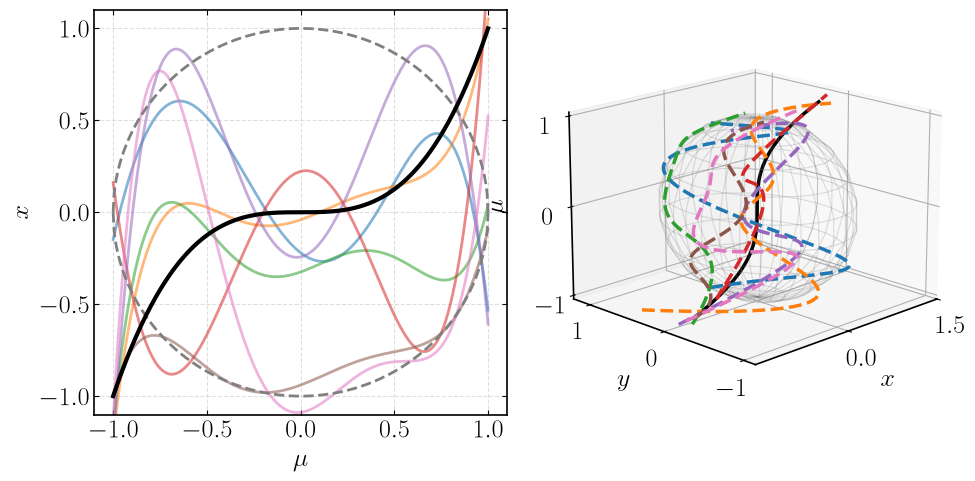

In [2]:
bounds = (-1.0, 1.0)
N = 5
solver = PCEGalerkin(rhs, jac, mu_bounds=bounds, state_dim=2, quad_order=2 * N + 1)
roots = solver.random_roots(N, n_samples=7, seed=42, scale=0.5)
print(f"Found {len(roots)} roots on {bounds}")

mu_ex = np.linspace(bounds[0], bounds[1], 400)
r_ex = np.sqrt(np.maximum(1.0 - mu_ex**2, 0.0))
exact_cub = exact_cubic(bounds)

fig = plt.figure(figsize=(10, 5))
ax2d = fig.add_subplot(1, 2, 1)
ax3d = fig.add_subplot(1, 2, 2, projection="3d")

plot_2d(solver, roots, exact_cub, state_idx=0, branch_style="-", branch_lw=2.0,
        branch_zorder=2, branch_alpha=0.55, exact_lw=3.0, exact_zorder=5, ylabel=r"$x$",
        ylim=[-1.1, 1.1], ax=ax2d)
ax2d.plot(mu_ex, r_ex, "--", color="gray", lw=2.0, zorder=4)
ax2d.plot(mu_ex, -r_ex, "--", color="gray", lw=2.0, zorder=4)

plot_3d(solver, roots, exact_cub, idx_pair=(0, 1), labels=(r"$x$", r"$y$"), azim=-135, ax=ax3d)
add_sphere_wireframe(ax3d, bounds)

plt.tight_layout()
plt.show()

## 2. Degree continuation across domains of increasing width

Degree continuation for different intervals

Continuation on (-0.1, 0.1): 24 branches
Continuation on (-0.3, 0.3): 25 branches
Continuation on (-0.5, 0.5): 3 branches


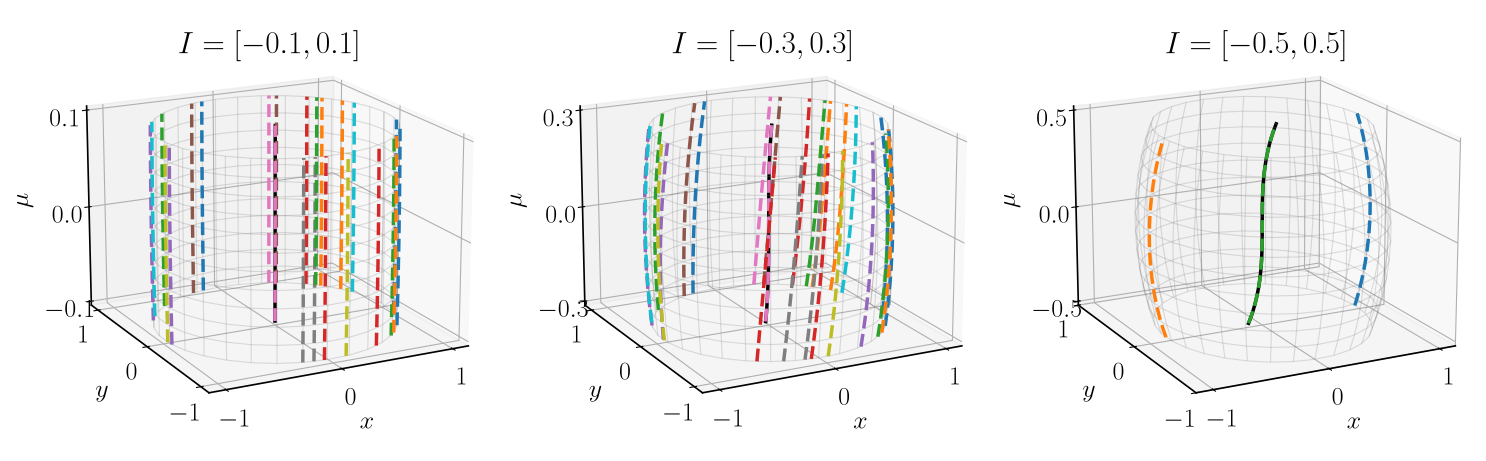

Continuation on (-0.7, 0.7): 3 branches
Continuation on (-1.0, 1.0): 6 branches
Continuation on (-1.2, 1.2): 3 branches


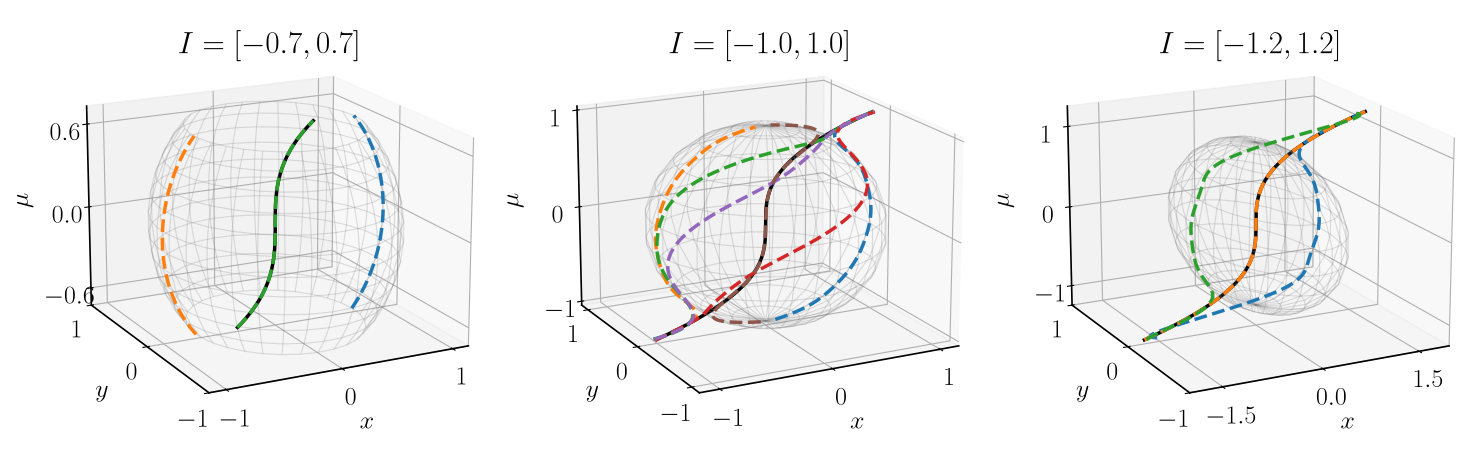

In [4]:
intervals = [(-0.1, 0.1), (-0.3, 0.3), (-0.5, 0.5),
             (-0.7, 0.7), (-1.0, 1.0), (-1.2, 1.2)]
N = 10

cols_size = 3
for i in range(0, len(intervals), cols_size):
    chunk = intervals[i : i + cols_size]
    
    fig = plt.figure(figsize=(15, 4.8))
    
    for idx, bnd in enumerate(chunk, start=1):
        s = PCEGalerkin(rhs, jac, mu_bounds=bnd, state_dim=2, quad_order=2 * N + 1)
        branches = s.find_branches(N, n_samples=25, seed=42, unique_tol=1e-3,
                                   box=(-1.2, 1.2), initialization=[[0.0, 0.0]])
        print(f"Continuation on {bnd}: {len(branches)} branches")

        ax = fig.add_subplot(1, len(chunk), idx, projection="3d")
        plot_3d(s, branches, exact_cubic(bnd), idx_pair=(0, 1), labels=(r"$x$", r"$y$"),
                title=rf"$I = [{bnd[0]}, {bnd[1]}]$", ax=ax)
        add_sphere_wireframe(ax, bnd)

    plt.tight_layout()
    plt.show()